In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cols = ["age","workclass","fnlwgt","education","education-num","marital-status",
        "occupation","relationship","race","sex","capital-gain","capital-loss",
        "hours-per-week","native-country","income"]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
df = pd.read_csv(url, names=cols, na_values="?", skipinitialspace=True)
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [16]:
print("Dimensions :", df.shape)
df.info()
print("Doublons :", df.duplicated().sum())

Dimensions : (32561, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
Doublons : 24


In [17]:
manquants = df.isna().sum()
print(manquants[manquants > 0])
print((df.isna().mean() * 100).round(2)[manquants > 0])

workclass         1836
occupation        1843
native-country     583
dtype: int64
workclass         5.64
occupation        5.66
native-country    1.79
dtype: float64


In [18]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


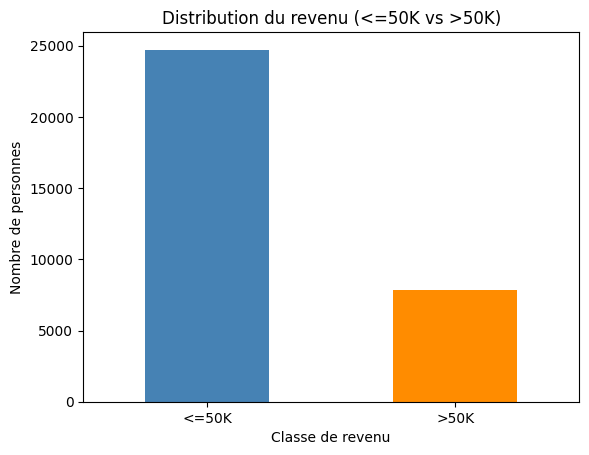

In [19]:
print(df["income"].value_counts(normalize=True).round(3))
df["income"].value_counts().plot(kind="bar", color=["steelblue", "darkorange"])
plt.title("Distribution du revenu (<=50K vs >50K)")
plt.ylabel("Nombre de personnes")
plt.xticks(rotation=0)
plt.xlabel("Classe de revenu")
plt.show()

La variable cible income présente un déséquilibre entre les deux classes. Environ 76 % des individus appartiennent à la classe <=50K, contre 24 % pour la classe >50K. Ce déséquilibre devra être pris en considération lors de l'évaluation des modèles de classification.

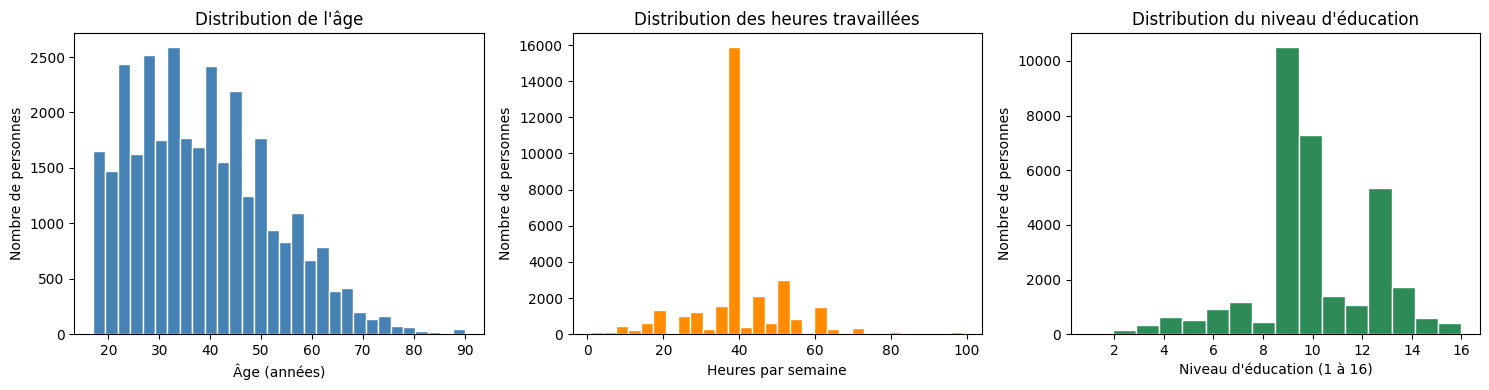

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["age"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution de l'âge")
axes[0].set_xlabel("Âge (années)")
axes[0].set_ylabel("Nombre de personnes")

axes[1].hist(df["hours-per-week"], bins=30, color="darkorange", edgecolor="white")
axes[1].set_title("Distribution des heures travaillées")
axes[1].set_xlabel("Heures par semaine")
axes[1].set_ylabel("Nombre de personnes")

axes[2].hist(df["education-num"], bins=16, color="seagreen", edgecolor="white")
axes[2].set_title("Distribution du niveau d'éducation")
axes[2].set_xlabel("Niveau d'éducation (1 à 16)")
axes[2].set_ylabel("Nombre de personnes")

plt.tight_layout()
plt.show()

L'âge est principalement concentré entre 25 et 50 ans. Le nombre d'heures travaillées par semaine présente un pic important autour de 40 heures. Les variables capital-gain et capital-loss présentent des distributions très asymétriques, avec une majorité de valeurs égales à zéro.

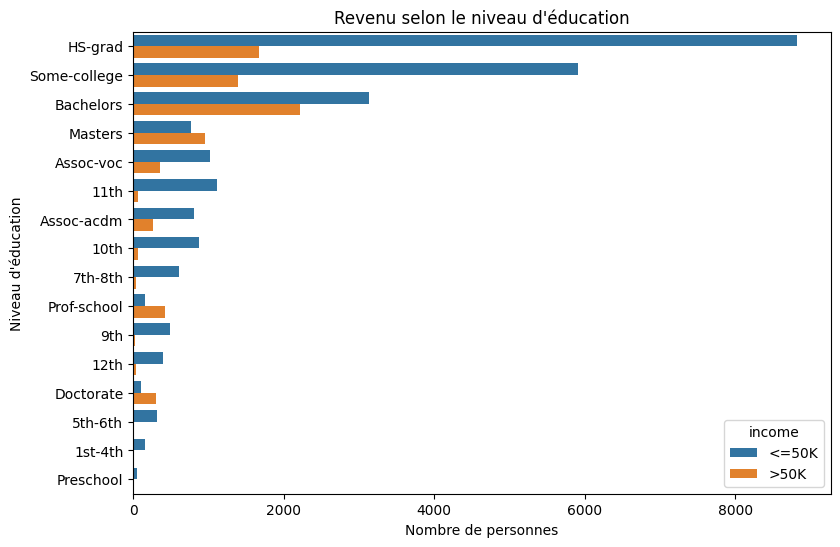

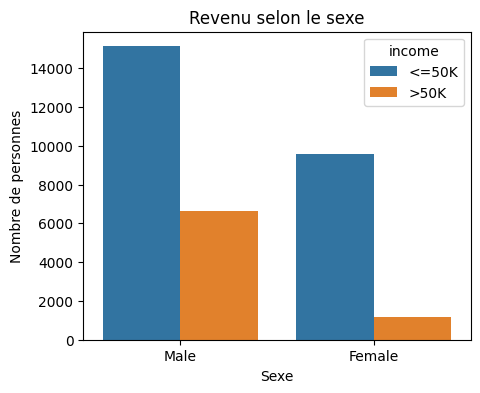

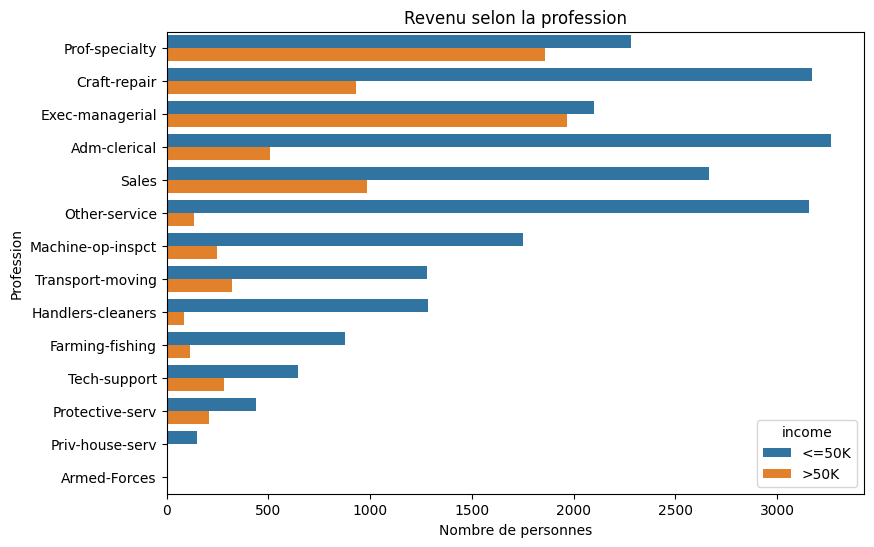

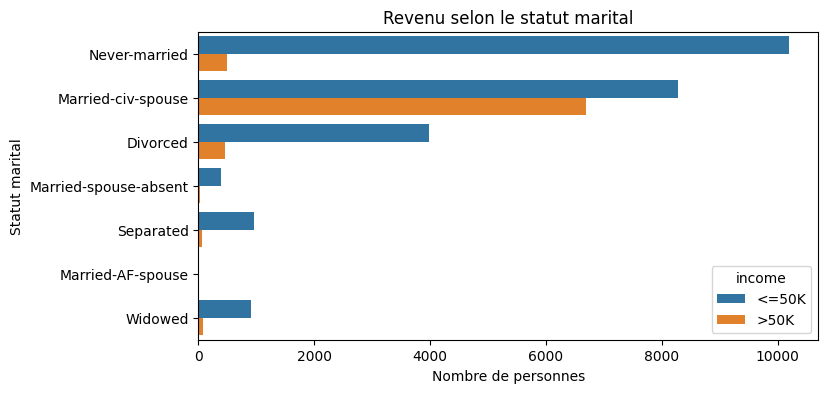

In [21]:
plt.figure(figsize=(9, 6))
sns.countplot(data=df, y="education", hue="income",
              order=df["education"].value_counts().index)
plt.title("Revenu selon le niveau d'éducation")
plt.xlabel("Nombre de personnes")
plt.ylabel("Niveau d'éducation")
plt.show()

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="sex", hue="income")
plt.title("Revenu selon le sexe")
plt.xlabel("Sexe")
plt.ylabel("Nombre de personnes")
plt.show()

plt.figure(figsize=(9, 6))
sns.countplot(data=df, y="occupation", hue="income",
              order=df["occupation"].value_counts().index)
plt.title("Revenu selon la profession")
plt.xlabel("Nombre de personnes")
plt.ylabel("Profession")
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(data=df, y="marital-status", hue="income")
plt.title("Revenu selon le statut marital")
plt.xlabel("Nombre de personnes")
plt.ylabel("Statut marital")
plt.show()

**Observation :**

Le statut marital semble fortement lié au niveau de revenu. Les personnes mariées avec un conjoint civil (Married-civ-spouse) présentent la proportion la plus élevée de revenus supérieurs à 50K, avec environ 44,7 %. À l'inverse, les personnes jamais mariées (Never-married) présentent une proportion de seulement 4,6 %. Cette différence montre que le statut marital constitue une variable intéressante pour prédire le revenu.

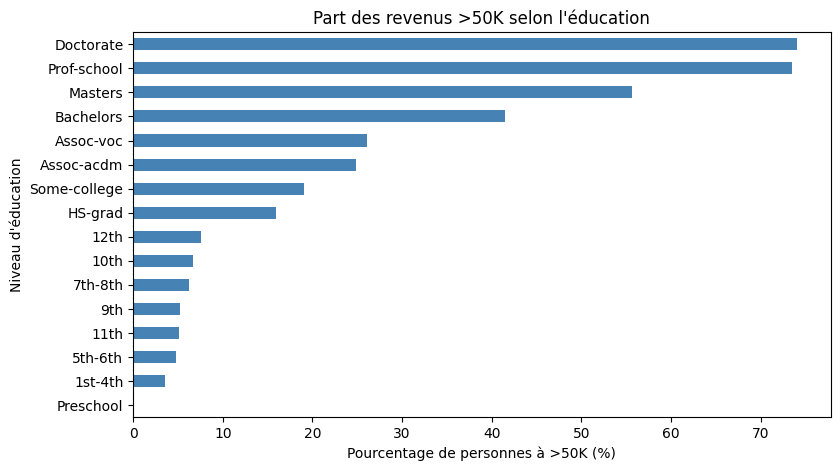

In [22]:
df["high_income"] = (df["income"] == ">50K").astype(int)

plt.figure(figsize=(9, 5))
(df.groupby("education")["high_income"].mean().sort_values() * 100).plot(kind="barh", color="steelblue")
plt.title("Part des revenus >50K selon l'éducation")
plt.xlabel("Pourcentage de personnes à >50K (%)")
plt.ylabel("Niveau d'éducation")
plt.show()

**Observation :**

On remarque que la proportion des personnes ayant un revenu supérieur à 50K augmente généralement avec le niveau d'éducation. Elle est de 16 % pour les personnes ayant un niveau HS-grad, de 41,5 % pour les titulaires d'un Bachelor et dépasse 73 % pour les niveaux Prof-school et Doctorate. Cela montre qu'il existe une relation importante entre le niveau d'éducation et le revenu.

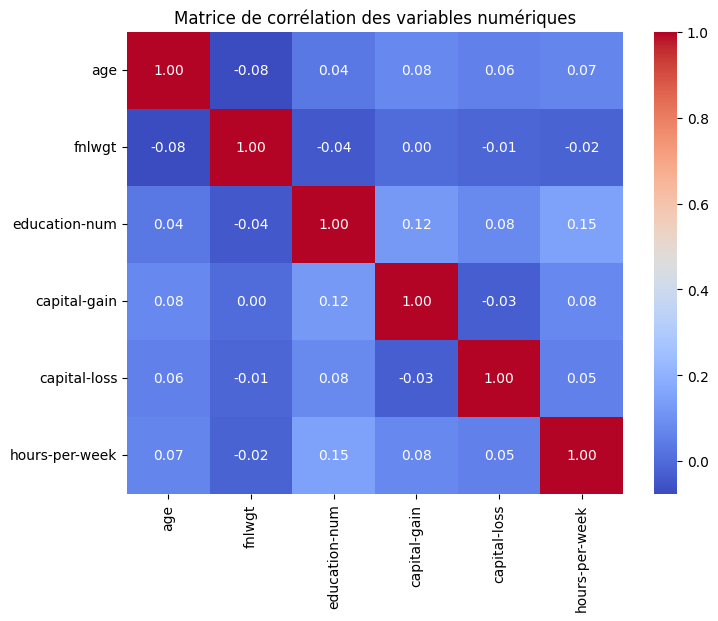

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes("number").drop(columns="high_income").corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation des variables numériques")
plt.show()

La matrice de corrélation montre que les relations linéaires entre les variables numériques sont globalement faibles. Aucune forte corrélation entre les variables explicatives numériques ne semble apparaître. Cela indique une faible multicolinéarité apparente.

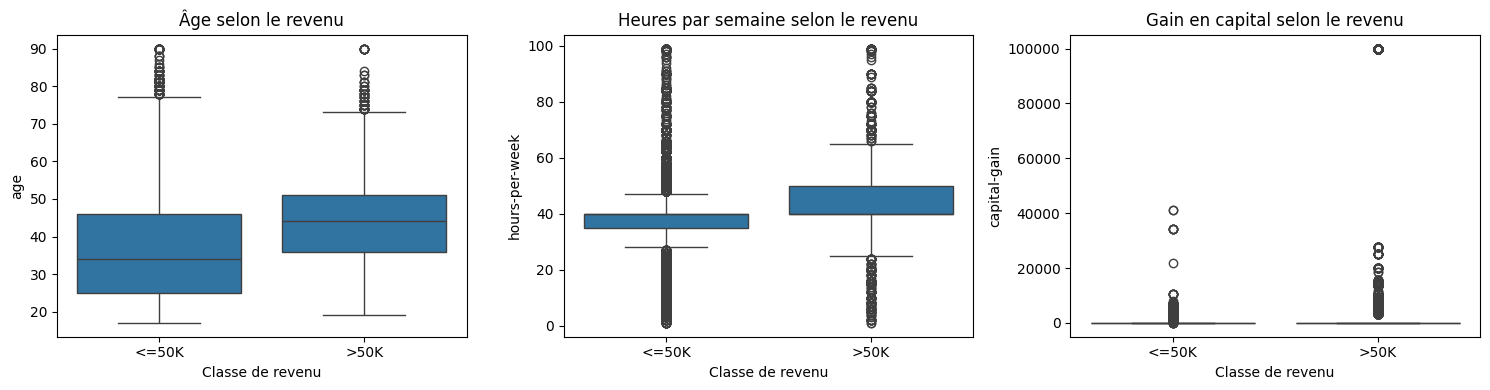

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="income", y="age", ax=axes[0])
axes[0].set_title("Âge selon le revenu")
sns.boxplot(data=df, x="income", y="hours-per-week", ax=axes[1])
axes[1].set_title("Heures par semaine selon le revenu")
sns.boxplot(data=df, x="income", y="capital-gain", ax=axes[2])
axes[2].set_title("Gain en capital selon le revenu")
for ax in axes:
    ax.set_xlabel("Classe de revenu")
plt.tight_layout()
plt.show()

Les boxplots permettent de comparer la distribution des variables numériques selon le niveau de revenu. On remarque notamment des différences possibles concernant l'âge et les heures travaillées. Les variables capital-gain et capital-loss présentent également des valeurs extrêmes, ce qui montre la nécessité d'examiner leur distribution avant la modélisation.

In [25]:
print(df.groupby("education")["income"].apply(lambda s: (s == ">50K").mean()).round(3).sort_values())
print(df.groupby("sex")["income"].apply(lambda s: (s == ">50K").mean()).round(3))
print(df.groupby("marital-status")["income"].apply(lambda s: (s == ">50K").mean()).round(3).sort_values())

education
Preschool       0.000
1st-4th         0.036
5th-6th         0.048
11th            0.051
9th             0.053
7th-8th         0.062
10th            0.066
12th            0.076
HS-grad         0.160
Some-college    0.190
Assoc-acdm      0.248
Assoc-voc       0.261
Bachelors       0.415
Masters         0.557
Prof-school     0.734
Doctorate       0.741
Name: income, dtype: float64
sex
Female    0.109
Male      0.306
Name: income, dtype: float64
marital-status
Never-married            0.046
Separated                0.064
Married-spouse-absent    0.081
Widowed                  0.086
Divorced                 0.104
Married-AF-spouse        0.435
Married-civ-spouse       0.447
Name: income, dtype: float64
